In [1]:
import os
os.chdir(os.path.expanduser("~/github/DATASCI266-Banking77-Encoder-vs-Decoder"))

In [2]:
import pandas as pd
import numpy as np
import glob
import json
import os; print(os.getcwd())

labels = json.load(open("data/raw/label_names.json"))

/Users/shuchivardan/github/DATASCI266-Banking77-Encoder-vs-Decoder


In [3]:
ls results/qwen_sft_* | wc -l

      48


In [4]:
import glob, os
print(os.getcwd())
files = sorted(glob.glob("/Users/shuchivardan/github/DATASCI266-Banking77-Encoder-vs-Decoder/results/qwen_sft_*.csv"))
print(f'Found {len(files)} files')

/Users/shuchivardan/github/DATASCI266-Banking77-Encoder-vs-Decoder
Found 48 files


In [5]:
files = sorted(glob.glob("results/qwen_sft_*.csv"))
print(f'Found {len(files)} files')

Found 48 files


In [6]:
#check the results file:
sample = pd.read_csv(files[0])
print(sample.head(2))
print(f'\nColumns: {list(sample.columns)}')
print(f'\n Rows: {len(sample)}')

      model     type budget  seed split  example_id  true_label  \
0  qwen_sft  decoder   full     0  test           0          11   
1  qwen_sft  decoder   full     0  test           1          11   

   predicted_label           raw_output  
0               41  lost_or_stolen_card  
1               11         card_arrival  

Columns: ['model', 'type', 'budget', 'seed', 'split', 'example_id', 'true_label', 'predicted_label', 'raw_output']

 Rows: 3080


In [7]:
# for the analysis table, need to extract cols with names 'budget', 'seed', 'split'

#check the file name:
print(files[0])

name = files[0].split('/')[-1].replace('.csv', '')
parts = name.split('_')
print(parts)

budget = parts[2]
seed = int(parts[3].replace('seed', ''))
split = parts[4]                         # 'test'
print(f"Budget: {budget}, Seed: {seed}, Split: {split}")


results/qwen_sft_full_seed0_test.csv
['qwen', 'sft', 'full', 'seed0', 'test']
Budget: full, Seed: 0, Split: test


In [8]:
# accuracy = how many predictions matched the true label
df = pd.read_csv(files[0])

correct = df["predicted_label"] == df["true_label"]  # True/False for each row
accuracy = correct.mean()                             # fraction that are True

print(f"Correct: {correct.sum()} out of {len(df)}")
print(f"Accuracy: {accuracy:.3f}")

Correct: 2900 out of 3080
Accuracy: 0.942


In [9]:
# same logic as above, but for every file
rows = []

for f in sorted(files):
    # parse filename
    name = f.split("/")[-1].replace(".csv", "")
    parts = name.split("_")
    budget = parts[2]
    seed = int(parts[3].replace("seed", ""))
    split = parts[4]
    
    # calculate accuracy
    df = pd.read_csv(f)
    acc = (df["predicted_label"] == df["true_label"]).mean()
    
    # store it
    rows.append({
        "budget": budget,
        "seed": seed,
        "split": split,
        "accuracy": round(acc, 3),
    })

results = pd.DataFrame(rows)
print(f"Total rows: {len(results)}")
print(results.head(10))

Total rows: 48
  budget  seed split  accuracy
0   full     0  test     0.942
1   full     0   val     0.943
2   full     1  test     0.940
3   full     1   val     0.938
4   full     2  test     0.936
5   full     2   val     0.927
6    k10     0  test     0.818
7    k10     0   val     0.834
8    k10     1  test     0.829
9    k10     1   val     0.852


In [10]:
# group by budget and split, take the mean of the 3 seeds
summary = (results
    .groupby(["budget", "split"])["accuracy"]
    .mean()
    .unstack("split")  # puts val and test as columns side by side
    .reindex(["k1", "k3", "k5", "k10", "k20", "k30", "p50", "full"])  # order by size
)

# add the difference column
summary["delta"] = summary["test"] - summary["val"]
summary = summary.round(3)

print("Qwen SFT: Val vs Test (mean across 3 seeds)")
print("=" * 50)
print(summary)

Qwen SFT: Val vs Test (mean across 3 seeds)
split    test    val  delta
budget                     
k1      0.494  0.475  0.019
k3      0.646  0.632  0.014
k5      0.744  0.740  0.003
k10     0.831  0.847 -0.016
k20     0.880  0.885 -0.005
k30     0.908  0.902  0.006
p50     0.924  0.925 -0.002
full    0.939  0.936  0.003


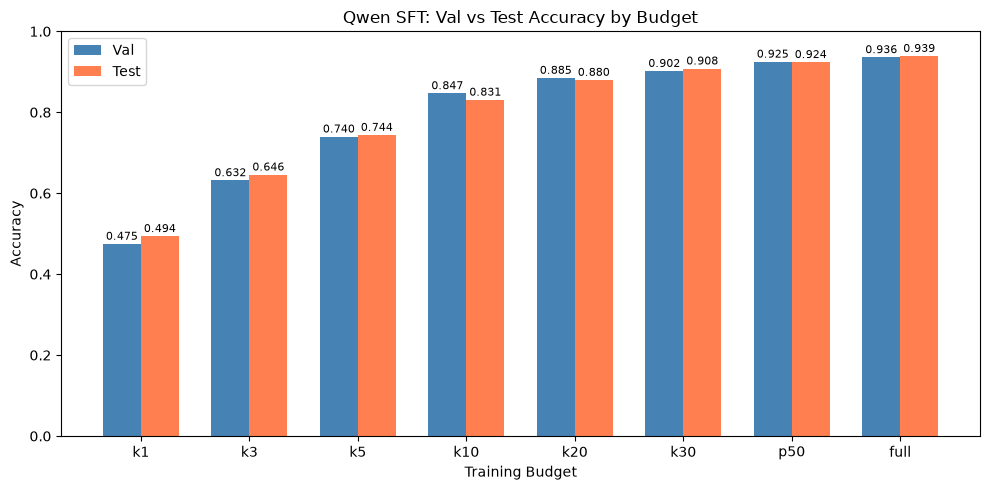

In [11]:
import matplotlib.pyplot as plt

budgets = list(summary.index)   # same order as the table, includes full
val_means = summary["val"].values
test_means = summary["test"].values

x = range(len(budgets))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar([i - width/2 for i in x], val_means, width, label="Val", color="steelblue")
ax.bar([i + width/2 for i in x], test_means, width, label="Test", color="coral")

ax.set_xlabel("Training Budget")
ax.set_ylabel("Accuracy")
ax.set_title("Qwen SFT: Val vs Test Accuracy by Budget")
ax.set_xticks(x)
ax.set_xticklabels(budgets)
ax.set_ylim(0, 1.0)
ax.legend()

# add accuracy values on top of each bar
for i in x:
    ax.text(i - width/2, val_means[i] + 0.01, f"{val_means[i]:.3f}", ha="center", fontsize=8)
    ax.text(i + width/2, test_means[i] + 0.01, f"{test_means[i]:.3f}", ha="center", fontsize=8)

plt.tight_layout()
plt.show()